# Lab 1: post performance relative to author history

## Protocol

Dev uses author-disjoint outer splits (seeds 42 and 137). Calibration authors fit the stack and decision multipliers. The final recipe repeats this on all official training authors.

In [1]:
from pathlib import Path
import json,sys,subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'improved.py').is_file() and (p/'lab1_submission/metrics.json').is_file())
OUT=ROOT/'lab1_submission'
analysis=json.loads((OUT/'analysis.json').read_text())
selection=json.loads((OUT/'selection.json').read_text())
metrics=json.loads((OUT/'metrics.json').read_text())
classes=['below','typical','above']
plt.rcParams.update({'figure.figsize':(8,3.8),'axes.spines.top':False,'axes.spines.right':False})
display(pd.DataFrame([analysis['population']]))

,train_posts,train_authors,test_posts,test_authors
0,71395,3295,17623,824


## Data and EDA

Train-only summaries from the selected feature table. Test labels were not used.

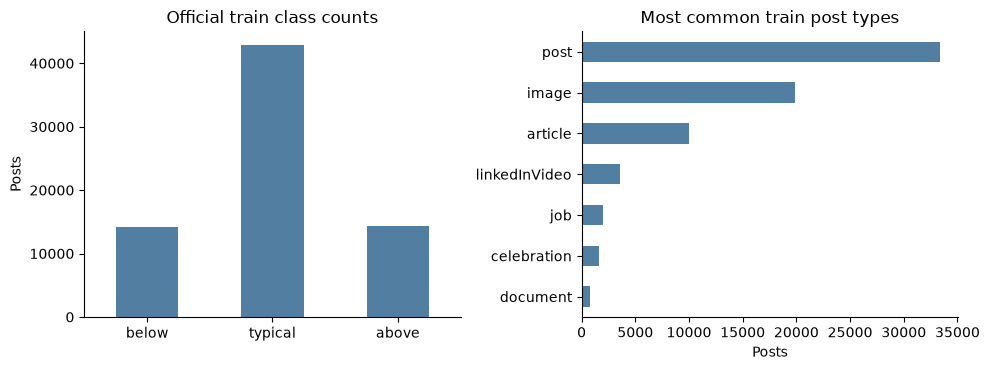

,Previous own posts
0.0,5.0
0.25,10.0
0.5,18.0
0.75,28.0
0.9,36.0
1.0,49.0


Missing age_days fraction: 0.0886


In [2]:
counts=pd.Series(analysis['eda']['class_counts']).rename(index=dict(enumerate(classes)))
counts.index=classes
fig,axes=plt.subplots(1,2,figsize=(10,3.8))
counts.plot.bar(ax=axes[0],rot=0,color='#527ea2',title='Official train class counts')
axes[0].set_ylabel('Posts')
pd.Series(analysis['eda']['content_types']).head(7).plot.barh(ax=axes[1],color='#527ea2',title='Most common train post types')
axes[1].invert_yaxis();axes[1].set_xlabel('Posts')
fig.tight_layout();plt.show()
display(pd.Series(analysis['eda']['history_quantiles'],name='Previous own posts').to_frame())
print('Missing age_days fraction:',round(analysis['eda']['missing_age_days_fraction'],4))

## Selected method

A logistic stack (C=0.1) combines four components:

1. CatBoost, 700 iterations, depth 6. Native post text, author history, post structure and CLIP visual features.
2. E5-base MLP, hidden 128, 20 epochs. Frozen multilingual text embeddings, previous-text similarity and difference, metadata.
3. History model, hidden 128, 12 epochs. Embeddings and outcomes of up to 20 earlier own posts, uniformly pooled.
4. CDF MLP, hidden 256, 20 epochs. Text and context plus the author's frequencies of earlier reactions below and above the class boundaries.

The stack uses component log-odds, author level, history size and spread, the reshare flag, and their interactions. Class decision multipliers are tuned on calibration authors. They change decisions, not calibrated probabilities.

Features use only earlier posts. Current-post reactions, labels and IDs are excluded. The fixed configuration is in `solution/config.json`.

## Development and grouped ablation

Pooled three-fold author-CV macro-F1 is 0.6762. These exploratory dev results may be optimistic from model selection and training-size differences.

In [3]:
development=[]
for seed,result in analysis['development'].items():
    development.append({'author split':seed,**{name:result[name] for name in ['macro_f1','qwk','accuracy']}})
display(pd.DataFrame(development).set_index('author split'))
print('Pooled3-fold author-CV macro-F1:',analysis['author_cv_macro_f1'])
rows=[]
for group in ['history','content','visual','time','collection','followers']:
    row={'removed group':group}
    for seed in ['42','137']:
        item=analysis['ablation'][seed]['-'+group]
        row[f'delta seed{seed}, pp']=100*item['delta']
        row[f'95% interval seed{seed}, pp']=f"[{100*item['ci'][0]:+.2f}; {100*item['ci'][1]:+.2f}]"
    rows.append(row)
display(pd.DataFrame(rows).set_index('removed group'))

,macro_f1,qwk,accuracy
author split,,,
42,0.686147,0.628751,0.721955
137,0.684788,0.624240,0.723511


Pooled3-fold author-CV macro-F1: 0.6761886786137278


,"delta seed42, pp","95% interval seed42, pp","delta seed137, pp","95% interval seed137, pp"
removed group,,,,
history,-14.06,[-15.49; -12.64],-12.20,[-13.74; -10.65]
content,-2.17,[-2.78; -1.64],-2.60,[-3.25; -1.97]
visual,-0.28,[-0.69; +0.14],-0.20,[-0.67; +0.28]
time,-0.30,[-0.63; +0.05],-0.32,[-0.75; +0.06]
collection,-0.40,[-0.72; -0.10],-0.15,[-0.57; +0.22]
followers,-0.27,[-0.62; +0.07],-0.22,[-0.75; +0.23]


Each ablation removes one feature group from a fixed CatBoost setup (185 numerical and 3 categorical features, no native text, two initializations). Multipliers are refitted after each removal. Overlapping effects cannot be added.

History is the largest signal. It captures each author's personal norm and its dynamics. Post structure and text add information about the current post. The collection group (`age_days`, `crawled_day`, `hist_n`) has a small effect. That does not show `age_days` alone is harmless.

Two variants did not improve both dev splits, so they were dropped. Full E5-small adaptation changed stack macro-F1 by +0.12/−0.28 percentage points. Frozen-text residual correction changed it by +0.07/−0.26 points.

## Fixed official-test result

The final four-component recipe was fixed before the test evaluation. Its CSV covers all 17,623 test posts. The table and confusion matrix below read the saved evaluation. Baseline macro-F1 on the full test is 0.5410. The README's Claude reference uses 2,000 posts, so it is not directly comparable.

,macro_f1,qwk,accuracy
model,,,
Official baseline,0.541000,0.457600,0.546500
Selected solution,0.668312,0.613428,0.706974


,precision,recall,f1-score,support
below,0.578489,0.525558,0.550755,3541.0
typical,0.749354,0.773425,0.761199,10491.0
above,0.694243,0.691729,0.692984,3591.0


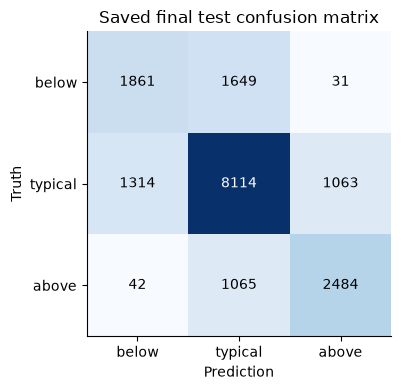

Predictions: 17623 unique post keys


In [4]:
result=metrics['test']
display(pd.DataFrame([{'model':'Official baseline','macro_f1':.5410,'qwk':.4576,'accuracy':.5465},
    {'model':'Selected solution',**{k:result[k] for k in ['macro_f1','qwk','accuracy']}}]).set_index('model'))
display(pd.DataFrame(result['classes']).T)
cm=np.asarray(result['confusion_matrix'])
fig,ax=plt.subplots(figsize=(5,4))
ax.imshow(cm,cmap='Blues');ax.set(xticks=range(3),yticks=range(3),xticklabels=classes,yticklabels=classes,
    xlabel='Prediction',ylabel='Truth',title='Saved final test confusion matrix')
for i in range(3):
    for j in range(3):ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
fig.tight_layout();plt.show()
pred=pd.read_csv(OUT/'predictions.csv')
assert len(pred)==17623 and not pred[['author','post']].duplicated().any() and pred.label.isin([0,1,2]).all()
print('Predictions:',len(pred),'unique post keys')

Below is underpredicted on test: recall 0.53 and F1 0.55, versus about 0.58 F1 on dev seed 42. This is not a basis for changing thresholds.

## Reproduction

The repo adds `improved.py`, `solution/` and the `kairos/` model-support modules to the baseline. Unpack the core release, including images, into `data/`. Videos are not needed. Install with `uv sync --frozen`, or install `requirements.txt` into `.venv`. See the [README](README.md#run).

From the repository root:
```bash
.venv/bin/python improved.py prepare
.venv/bin/python improved.py train --model-dir models/retrained --output lab1_submission_reproduced
.venv/bin/python improved.py predict --model-dir models/retrained --output lab1_submission_reproduced
```

Prepare reuses matching cached encodings. Otherwise it computes them from the raw release, using the encoder revisions in `solution/config.json`. Weights in `models/best/` are not in the repo. Reruns may differ numerically on other hardware.

On Apple M4, training took about 11 minutes, E5-base encoding 44 minutes and image extraction 22 minutes. These are separate stages, not a full run. RTX 4070 timing was not measured.

To rerun the saved evaluation:
```bash
.venv/bin/python evaluate.py --predictions lab1_submission_reproduced/predictions.csv
```
The notebook does not run this. The cell below reproduces predictions only if local weights and feature caches exist.

In [5]:
config = json.loads((ROOT/'solution/config.json').read_text())
cache_names = [component['cache'] for component in config['components']]
cache_ready = all((ROOT/'work'/f'{name}.pkl').is_file() for name in cache_names)
if (ROOT/'models/best/model.joblib').is_file() and cache_ready:
    subprocess.run([sys.executable,str(ROOT/'improved.py'),'predict'],cwd=ROOT,check=True)
else:
    print('Local selected weights and all feature caches are required. Run the prepare/train commands above to reproduce.')

Existing predictions match exactly: 17623 /Users/endorflem/ITMO/SocialMediaAnal/lab1/lab1_submission/predictions.csv
SHA256: 2732511ec9d899428ae81ef2c7102499e3775b46d05910087716eaa925e6abc8


## Limitations and conclusion

Macro-F1 improved from the official baseline 0.5410 to 0.6683. The target 0.70 was not reached.

Limitations:

- Dev splits and CV folds were reused during the search.
- The test was seen earlier with an older model, so 0.6683 is not a new independent test score.
- The model uses crawl age (`age_days`), and engagement is a crawl-time snapshot.
- History is truncated, and early-history image coverage is incomplete.
- Results do not show performance on other platforms or real-time forecasting.